In [1]:
%pylab inline

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


In [104]:
import scipy
import pickle
import numpy
import pandas as pd
from sklearn.decomposition import PCA
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_distances
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score  
from PIL import Image

In [117]:
import os
os.environ["TOKENIZERS_PARALLELISM"] = "false"

In [3]:
model = SentenceTransformer("all-MiniLM-L6-v2")

In [27]:
embeddings=dict()
#reservoir_embeddings = [model.encode(p) for p in reservoir]
for temp in [0.1,0.3,0.5,0.7,0.9,1.1,1.3]:
    for n in range(100):
        filename=f"resultsNew/temps_{temp}/logs/run_{n:03}_rep_0_temp_{temp}.csv"
        data=pd.read_csv(filename)
        #if len(data)<100:
            #print(f"incomplete {temp} {n} {len(data)}")
            #print(f"python test.py {n} 1 {temp}")
            #print(f"sbatch --array={n} --export=ALL,temp={temp},save=0 newRunThis.sb")
        #while all frames have been computed, rarely the last prompt wasn't added, this compensates for this phenomenon, reusing the last embedding again
        R=[model.encode(p) for p in data["prompt"]]
        while len(R)<100:
            R.append(R[-1])
        embeddings[f"{temp} {n}"]=R

In [28]:
pickle.dump(embeddings,open("allNewEmbeddingsForAllPaths.p","wb"))

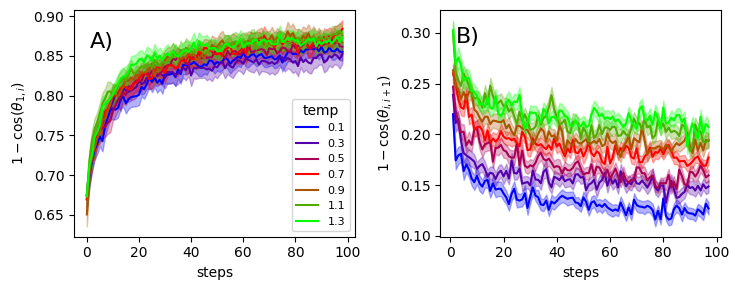

In [51]:
Ds=dict()
Ys=dict()
for temp in [0.1,0.3,0.5,0.7,0.9,1.1,1.3]:
    Y=[]
    D=[]
    for n in range(100):
        M=numpy.array(embeddings[f"{temp} {n}"])
        dists = cosine_distances(M)
        Y.append(dists[0][1:])
        d=[]
        for i in range(1,99):
            d.append(dists[i][i+1])
        D.append(d)
    Y=numpy.array(Y)
    D=numpy.array(D)
    Ds[temp]=D
    Ys[temp]=Y

# Choose a colormap (e.g., 'viridis', 'plasma', 'inferno', 'magma', 'cividis')
cmap = plt.get_cmap('brg')

plt.figure(figsize=[7.5,3])
plt.subplot(1,2,1)
for i,temp in enumerate([0.1,0.3,0.5,0.7,0.9,1.1,1.3]):
    m=Ys[temp].mean(0)
    s=Ys[temp].std(0)/numpy.sqrt(100)
    plt.fill_between(range(99),m+s,m-s,alpha=0.3,color=cmap(numpy.linspace(0,1,7)[i]))
    plt.plot(m,color=cmap(numpy.linspace(0,1,7)[i]),label=temp)
    plt.legend(title='temp',fontsize=8)
plt.xlabel("steps",fontsize=10)
plt.ylabel(r"$1 - \cos(\theta_{1,i})$")
plt.text(1,0.86,"A)",fontsize=16)    
plt.subplot(1,2,2)
for i,temp in enumerate([0.1,0.3,0.5,0.7,0.9,1.1,1.3]):
    m=Ds[temp].mean(0)
    s=Ds[temp].std(0)/numpy.sqrt(100)
    #last datapoint removed goes beyond the last image otherwise
    m=m[:-1]
    s=s[:-1]
    plt.fill_between(range(1,98),m+s,m-s,alpha=0.3,color=cmap(numpy.linspace(0,1,7)[i]))
    plt.plot(range(1,98),m,color=cmap(numpy.linspace(0,1,7)[i]))
    plt.xlabel("steps",fontsize=10)
    plt.ylabel(r"$1 - \cos(\theta_{i,i+1})$")
plt.text(2,0.29,"B)",fontsize=16)    
plt.tight_layout()
plt.savefig("newTrajectoriesThetaBoth.pdf")
plt.show()

t = 0.1: optimal k = 16
t = 0.3: optimal k = 16
t = 0.5: optimal k = 19
t = 0.7: optimal k = 16
t = 0.9: optimal k = 17
t = 1.1: optimal k = 17
t = 1.3: optimal k = 15


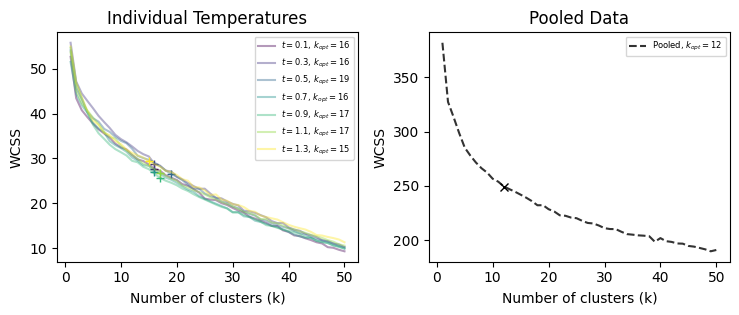


Pooled data optimal k: 12


In [63]:
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from matplotlib import cm

# Initialize figure
plt.figure(figsize=[7.5, 3.25])
cmap = cm.viridis

# =============================================
# Left subplot: Individual temperatures
# =============================================
plt.subplot(1, 2, 1)
clusterLabels = {}
randomSeed=1
for i, temp in enumerate([0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3]):
    # Load embeddings for current temperature
    EP = np.array([embeddings[f"{temp} {n}"][-1] for n in range(100)])
    
    # WCSS calculation
    k_range = range(1, 51)
    wcss = []
    CL = {}
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=randomSeed, n_init=10)
        kmeans.fit(EP)
        wcss.append(kmeans.inertia_)
        CL[k] = kmeans.predict(EP)
    
    # Find optimal k
    k_normalized = np.array(k_range) / max(k_range)
    wcss_normalized = np.array(wcss) / max(wcss)
    optimal_k = k_range[np.argmin(np.sqrt(k_normalized**2 + wcss_normalized**2))]
    
    # Plot
    plt.plot(k_range, wcss, linestyle='-', color=cmap(np.linspace(0, 1, 7)[i]),
             label=rf"$t={temp}$, $k_{{opt}}={optimal_k}$", alpha=0.4)
    plt.plot(optimal_k, wcss[optimal_k-1], marker='+', color=cmap(np.linspace(0, 1, 7)[i]))
    
    clusterLabels[temp] = CL[optimal_k]
    print(f"t = {temp}: optimal k = {optimal_k}")

plt.legend(fontsize=6)
plt.xlabel('Number of clusters (k)', fontsize=10)
plt.ylabel('WCSS', fontsize=10)
plt.title('Individual Temperatures', fontsize=12)

# =============================================
# Right subplot: Pooled data
# =============================================
plt.subplot(1, 2, 2)

# Create pooled dataset
pooled_EP = np.vstack([embeddings[f"{temp} {n}"][-1] 
                      for temp in [0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3] 
                      for n in range(100)])

# WCSS calculation for pooled data
wcss_pooled = []
CL_pooled = {}
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=randomSeed, n_init=10)
    kmeans.fit(pooled_EP)
    wcss_pooled.append(kmeans.inertia_)
    CL_pooled[k] = kmeans.predict(pooled_EP)

# Find optimal k for pooled data
k_normalized_pooled = np.array(k_range) / max(k_range)
wcss_normalized_pooled = np.array(wcss_pooled) / max(wcss_pooled)
optimal_k_pooled = k_range[np.argmin(np.sqrt(k_normalized_pooled**2 + wcss_normalized_pooled**2))]

# Store results
clusterLabels_pooled = CL_pooled[optimal_k_pooled]

# Plot pooled results
plt.plot(k_range, wcss_pooled, linestyle='--', color='black',
         label=rf"Pooled, $k_{{opt}}={optimal_k_pooled}$", alpha=0.8)
plt.plot(optimal_k_pooled, wcss_pooled[optimal_k_pooled-1], marker='x', color='black')

plt.legend(fontsize=6)
plt.xlabel('Number of clusters (k)', fontsize=10)
plt.ylabel('WCSS', fontsize=10)
plt.title('Pooled Data', fontsize=12)

# Final formatting
plt.tight_layout()
plt.savefig("newClusterOpimality.pdf")
plt.show()

print(f"\nPooled data optimal k: {optimal_k_pooled}")

In [64]:
pickle.dump(clusterLabels,open("newClusterLabels.p","wb"))
pickle.dump(clusterLabels_pooled,open("newPooledClusterLabels.p","wb"))
clusterLabels[0.1]

array([ 2,  0,  8,  0,  3,  8,  7,  7,  8,  3,  3,  2,  0,  4, 10, 10,  1,
        3,  3,  2,  4,  8,  7, 12,  4, 10,  0,  5, 14,  0,  8,  7, 12,  1,
       14,  8,  6,  8, 10, 11,  4, 13,  8, 11,  8, 14,  0,  2, 10,  5,  8,
        2,  8,  2, 12, 10,  8,  2,  8,  8, 14,  8,  3,  2, 10,  0,  8,  6,
        8, 11, 11,  7, 10,  6,  3,  3,  4,  5, 10,  2,  8,  4,  6,  2,  8,
        8,  8,  2,  1,  4,  2,  4,  4,  8,  1,  9, 10, 15,  2,  8],
      dtype=int32)

In [147]:
print(len(clusterLabels_pooled))
poolClustersEmbedding=dict()
poolClustersFilename=dict()
poolCentroid=dict()
where=0
for temp in [0.1, 0.3, 0.5, 0.7, 0.9, 1.1, 1.3]:
    for n in range(100):
        l=clusterLabels_pooled[where]
        if l not in poolClustersEmbedding:
            poolClustersEmbedding[l]=[]
            poolClustersFilename[l]=[]
        poolClustersEmbedding[l].append(embeddings[f"{temp} {n}"][-1])
        poolClustersFilename[l].append([temp,n])
        where+=1
buffer=16
I=Image.new('RGB', (512*12+(11*buffer), (512*4)+(4*buffer)), 'white')
xLoc=[6,1,2,4,3,10,0,7,8,9,5,11]
for i in range(12):
    four=[]
    print(i,len(poolClustersEmbedding[i]))
    poolClustersEmbedding[i]=numpy.array(poolClustersEmbedding[i])
    poolCentroid[i]=poolClustersEmbedding[i].mean(0)
    distances=cosine_similarity(poolClustersEmbedding[i],[poolCentroid[i]]).flatten()
    rank=list(numpy.argsort(distances))
    for f in range(4):
        four.append(poolClustersFilename[i][rank.index(f+4)])
        temp,theID=four[-1]
        source=Image.open(f'resultsNew/temps_{temp}/mosaics/run_{theID:03}_rep_0_temp_{temp}_grid_10x10.jpg')
        source_x=source_y=512*9
        subimage = source.crop((source_x, source_y, source_x+512, source_y+512))
        #run_045_rep_0_temp_0.1_grid_10x10.jpg
        I.paste(subimage, ((512+buffer)*xLoc[i], (512+buffer)*f))
    print(four)
I.save('testAggregate.jpg')

700
0 16
[[0.9, 20], [0.3, 3], [0.7, 95], [0.3, 45]]
1 44
[[0.1, 49], [1.3, 94], [1.1, 34], [0.9, 16]]
2 92
[[1.1, 80], [0.1, 0], [0.5, 61], [1.3, 98]]
3 143
[[0.7, 97], [0.1, 86], [0.7, 53], [0.1, 98]]
4 29
[[1.3, 91], [1.1, 45], [0.9, 22], [1.1, 25]]
5 51
[[0.3, 94], [0.9, 99], [0.5, 98], [0.7, 65]]
6 40
[[1.1, 36], [0.5, 73], [1.3, 41], [1.1, 55]]
7 67
[[0.9, 34], [0.9, 21], [0.1, 24], [0.5, 41]]
8 44
[[0.9, 89], [0.3, 22], [0.5, 48], [0.1, 28]]
9 79
[[0.5, 24], [0.9, 58], [0.1, 25], [0.3, 43]]
10 26
[[0.3, 74], [1.3, 22], [0.1, 48], [1.3, 72]]
11 69
[[0.1, 69], [0.1, 7], [1.1, 7], [1.1, 74]]


In [146]:
I=Image.new('RGB', (512*10, 512*10), 'white')
theID=0
temp=0.9
for x in range(10):
    for y in range(10):
        source=Image.open(f'resultsNew/temps_{temp}/mosaics/run_{theID:03}_rep_0_temp_{temp}_grid_10x10.jpg')
        source_x=source_y=512*9
        subimage = source.crop((source_x, source_y, source_x+512, source_y+512))
        I.paste(subimage, (512*x, 512*y))
        theID+=1
I.save("testEndpoints.jpg")